# Lab 2 적용 — 시각화와 데이터 준비 (Give Me Some Credit)

**Lab 1에서 넘어온 질문:** 극단값과 치우친 분포가 많은데, 이 값들을 그대로 써도 될까? 어떻게 바꿔야 할까?

Lab 2의 순서를 그대로 따른다.
1. 단변량 시각화: 히스토그램 → 밀도 → 박스플롯
2. 다변량 시각화: 상관행렬 → 산점도 행렬
3. 데이터 변환: MinMax(Rescale) → Standardise → Normalise → Binarise
4. 도전 과제: 원본 데이터와 변환 데이터에 결정트리를 돌려 비교 (10-fold)

Lab 2 본문의 "여러 변환(view)을 만들고 여러 알고리즘으로 시험해 보라"는 권고에 따라,
Lab 1 (e)에서 찾은 치우친 분포를 바로잡는 **로그 변환 view**를 하나 더 만들고,
변환이 "가중치를 쓰는 회귀 모델에 유용하다"는 설명을 확인하려고 **로지스틱 회귀**로도 비교한다.

In [1]:
import glob, os
import numpy
from pandas import read_csv
from matplotlib import pyplot, font_manager

for p in glob.glob(os.path.expandvars(r'%LOCALAPPDATA%\Microsoft\Windows\Fonts\Pretendard-*.ttf')):
    font_manager.fontManager.addfont(p)
pyplot.rcParams['font.family'] = 'Pretendard'
pyplot.rcParams['axes.unicode_minus'] = False
BLUE, RED, GRAY, INK = '#3182F6', '#F04452', '#B0B8C1', '#191F28'

filename = '../data/givemesomecredit.csv'
names = ['target', 'revol', 'age', 'late30', 'debt', 'income', 'depend', 'defaulted', 'loans']
data = read_csv(filename, names=names, header=0)
print(data.shape)

(150000, 9)


## 1. 단변량 시각화
### 1-1. 히스토그램 (Lab 2: `data.hist()`)

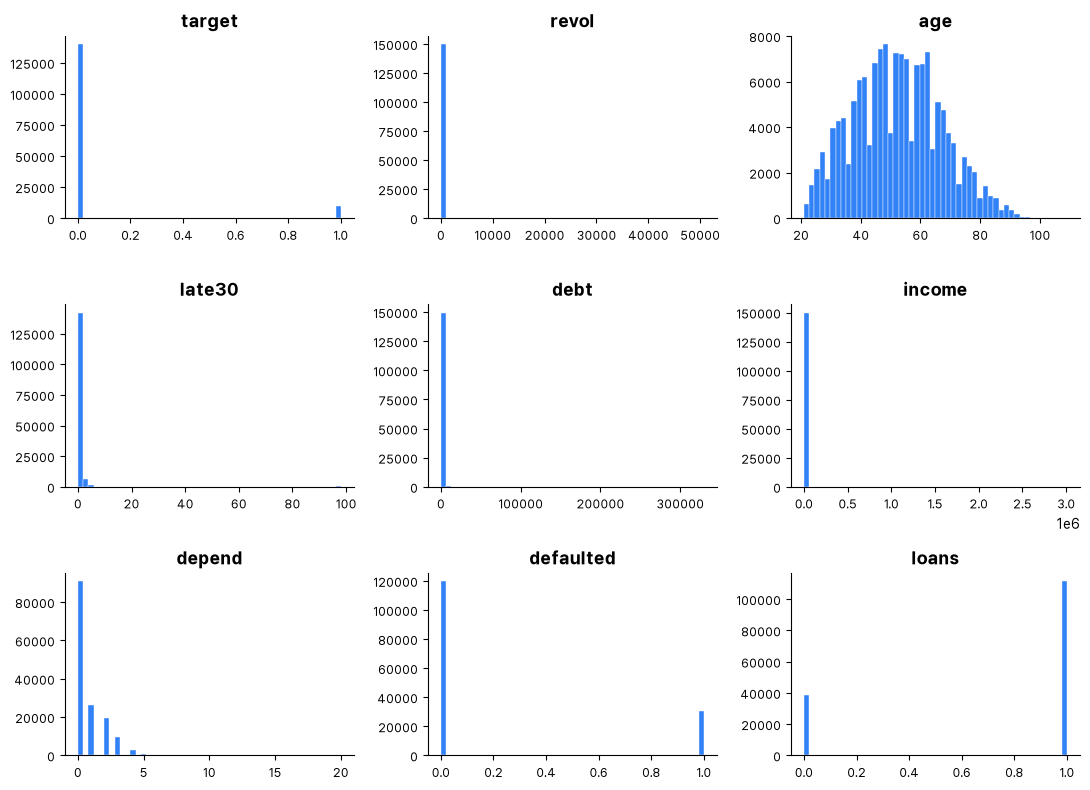

In [2]:
axes = data.hist(figsize=(11, 8), bins=50, color=BLUE, edgecolor='white', linewidth=0.3, grid=False)
for ax in axes.ravel():
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=9)
    ax.title.set_fontsize(13); ax.title.set_fontweight('bold')
pyplot.tight_layout()
pyplot.savefig('../figures/lab2_hist.png', dpi=200)
pyplot.show()

**(a) 그림 크기 조절:** `figsize=(11, 8)`로 키웠다. **(b) 기본 구간(bins) 수:** 10개. 15만 건에서는 너무 거칠어 50개로 늘렸다.

revol, late30, debt, income은 막대 하나에 거의 모든 값이 몰려 있다. 극단값 때문에 가로축이 수만~수백만까지 늘어났기 때문이다.

### 1-2. 밀도 그림 (Lab 2: `kind='density'`)

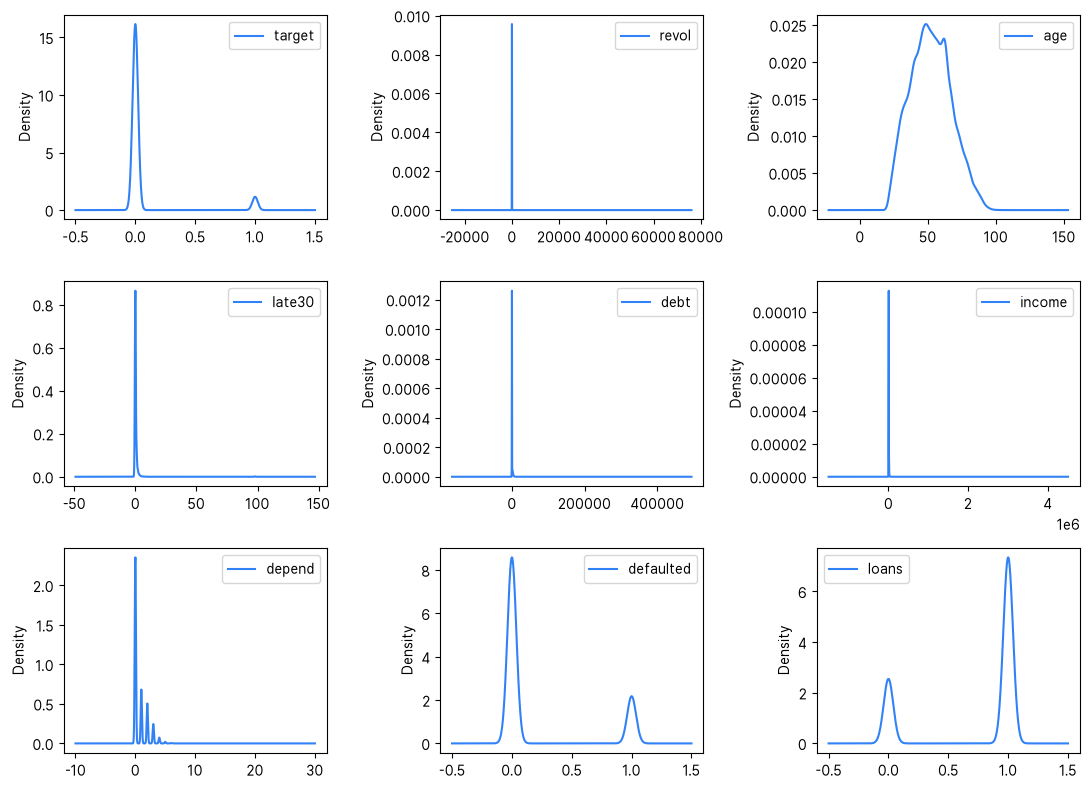

In [3]:
data.plot(kind='density', subplots=True, layout=(3, 3), sharex=False, figsize=(11, 8), legend=True, color=BLUE)
pyplot.tight_layout(); pyplot.show()

**(d)** pandas `plot`은 line, bar, barh, hist, box, kde/density, area, pie, scatter, hexbin 등 11가지 종류를 지원한다. **(e)** 박스플롯은 `kind='box'`.

### 1-3. 박스플롯 (Lab 2: `kind='box'`)

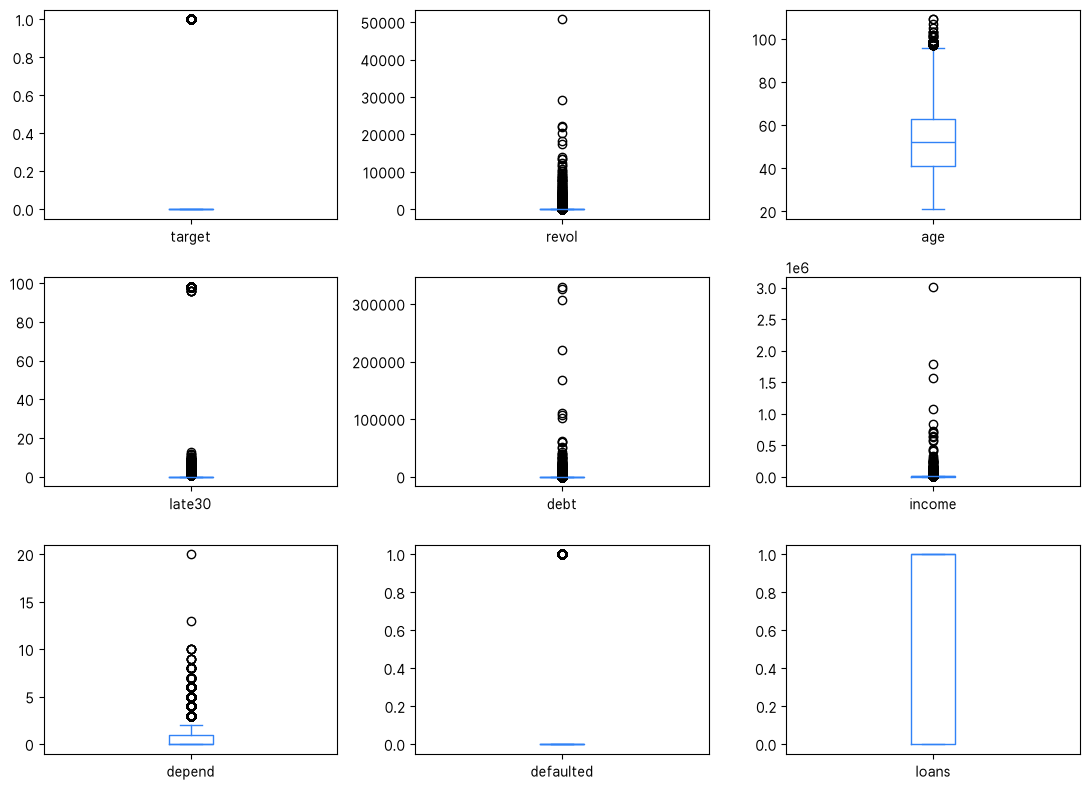

In [4]:
data.plot(kind='box', subplots=True, layout=(3, 3), sharex=False, sharey=False, figsize=(11, 8), color=BLUE)
pyplot.tight_layout()
pyplot.savefig('../figures/lab2_box.png', dpi=200)
pyplot.show()

**(f) 분류에 쓸 속성:** 박스플롯에서 revol, debt, income은 상자가 납작하고 점(이상치)만 길게 늘어서 있다.
그대로 쓰면 신호가 극단값에 묻힌다. 반면 defaulted, late30, age는 Lab 1에서 연체와의 상관이 뚜렷했다.
→ 속성을 버리기보다, **분포를 바로잡은 뒤** 모두 써 보는 것이 맞다 (Lab 3에서 특성 선택으로 다시 확인).

## 2. 다변량 시각화
### 2-1. 상관행렬 그림 (Lab 2: `matshow`)

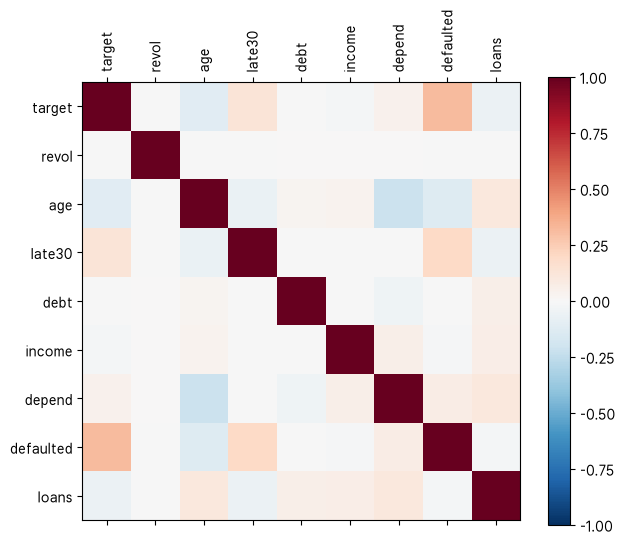

In [5]:
correlations = data.corr()
fig = pyplot.figure(figsize=(6.5, 5.5))
ax = fig.add_subplot(111)
cax = ax.matshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
fig.colorbar(cax)
ticks = numpy.arange(0, 9, 1)
ax.set_xticks(ticks); ax.set_yticks(ticks)
ax.set_xticklabels(names, rotation=90); ax.set_yticklabels(names)
pyplot.tight_layout()
pyplot.savefig('../figures/lab2_corr_matrix.png', dpi=200)
pyplot.show()

**(g)** 이름과 눈금을 빼면 일반적인 그림이 된다 (`ax.matshow(correlations)` + `colorbar`만). 대각선 외에는 진한 칸이 거의 없다 → 서로 겹치는 정보를 가진 변수 쌍이 없다.

### 2-2. 산점도 행렬 (Lab 2: `scatter_matrix`)

15만 개 점을 64칸에 모두 찍으면 점이 겹쳐 아무것도 보이지 않고 시간도 오래 걸린다.
**무작위 5,000건을 뽑아** 그린다 (15만 건을 다루는 첫 번째 고민).

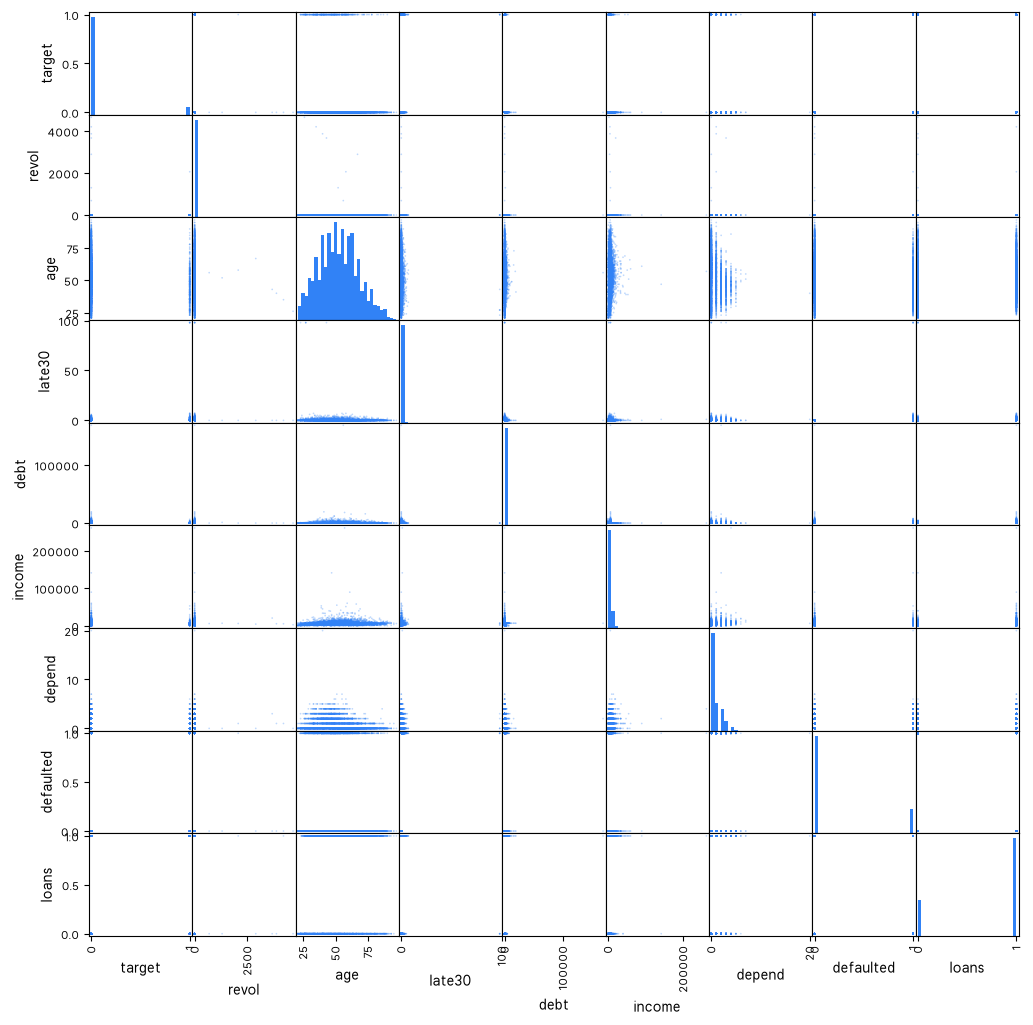

In [6]:
from pandas.plotting import scatter_matrix
sample = data.sample(5000, random_state=7)
scatter_matrix(sample, figsize=(12, 12), alpha=0.3, s=6, color=BLUE, hist_kwds={'color': BLUE, 'bins': 30})
pyplot.savefig('../figures/lab2_scatter_matrix.png', dpi=110)
pyplot.show()

**(h)** 산점도에서도 revol, debt, income은 점이 한쪽 모서리에 몰려 관계가 보이지 않는다. 선택할 속성이 바뀌기보다는, 변환이 먼저 필요하다는 결론은 같다.

## 3. 데이터 변환 (Lab 2의 4가지 + 로그 변환)

In [7]:
from numpy import set_printoptions
from sklearn.preprocessing import MinMaxScaler, StandardScaler, Normalizer, Binarizer
array = data.values
X = array[:, 1:9].astype(float)   # 이 데이터는 정답(target)이 첫 열 → Lab의 X = array[:,0:8]과 위치가 반대
Y = array[:, 0].astype(int)
set_printoptions(precision=3, suppress=True)

rescaledX = MinMaxScaler(feature_range=(0, 1)).fit_transform(X)
standardX = StandardScaler().fit(X).transform(X)
normalizedX = Normalizer().fit(X).transform(X)
binaryX = Binarizer(threshold=0.0).fit(X).transform(X)
print('원본       ', X[0])
print('MinMax     ', rescaledX[0])
print('Standard   ', standardX[0])
print('Normalizer ', normalizedX[0])
print('Binarizer  ', binaryX[0])

원본        [   0.766   45.       2.       0.803 9120.       2.       1.       1.   ]
MinMax      [0.    0.273 0.02  0.    0.003 0.1   1.    1.   ]
Standard    [-0.021 -0.494  0.377 -0.173  0.19   1.141  1.985  0.589]
Normalizer  [0.    0.005 0.    0.    1.    0.    0.    0.   ]
Binarizer   [1. 1. 1. 1. 1. 1. 1. 1.]


In [8]:
# (i)(j)(m)(n) 확인
print('MinMax 범위      :', rescaledX.min().round(3), '~', rescaledX.max().round(3))
print('Standard 평균/표준편차:', standardX.mean().round(3), '/', standardX.std().round(3))
print('Normalizer 행 길이:', numpy.linalg.norm(normalizedX, axis=1)[:3].round(3))
print('Normalizer 0번 행 :', normalizedX[0].round(3), ' ← 소득(income) 하나가 길이를 거의 다 차지')

MinMax 범위      : 0.0 ~ 1.0
Standard 평균/표준편차: -0.0 / 1.0
Normalizer 행 길이: [1. 1. 1.]
Normalizer 0번 행 : [0.    0.005 0.    0.    1.    0.    0.    0.   ]  ← 소득(income) 하나가 길이를 거의 다 차지


### 3-1. 로그 변환 view (Lab 1 (e)의 답)

치우친 4개 변수(revol, late30, debt, income)에 `log1p`(= log(1+x), 0도 처리 가능)를 적용한 뒤 표준화한다.

In [9]:
skewed = [names.index(c) - 1 for c in ['revol', 'late30', 'debt', 'income']]
Xlog = X.copy()
Xlog[:, skewed] = numpy.log1p(Xlog[:, skewed])
logX = StandardScaler().fit_transform(Xlog)
from pandas import DataFrame
skew_cmp = DataFrame({'원본 왜도': DataFrame(X, columns=names[1:]).skew(),
                      '로그 후 왜도': DataFrame(Xlog, columns=names[1:]).skew()}).round(1)
print(skew_cmp.loc[['revol', 'late30', 'debt', 'income']])

        원본 왜도  로그 후 왜도
revol    97.6     11.7
late30   22.6      4.3
debt     95.2      1.7
income  127.4     -4.9


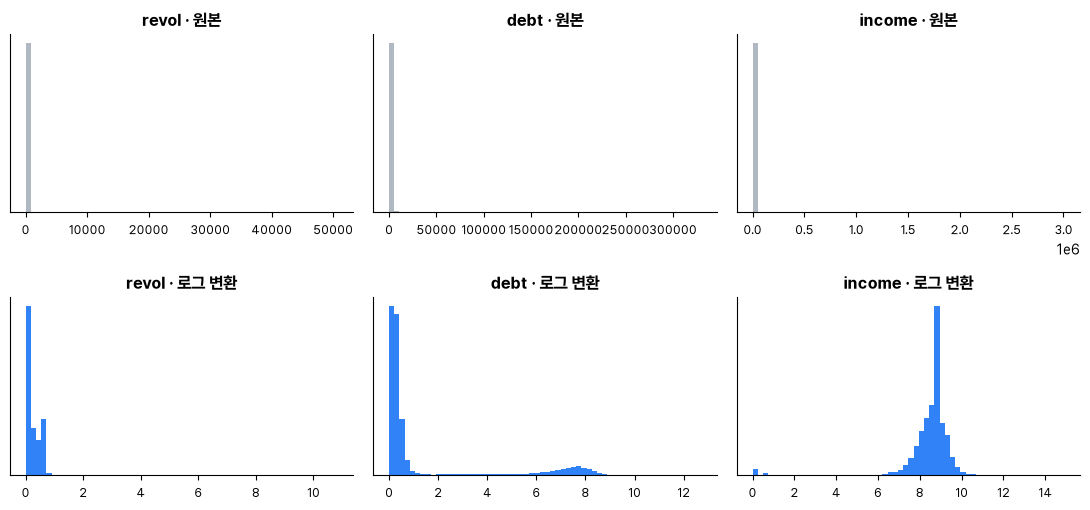

In [10]:
# 그림: 로그 변환 전후 분포
fig, axes = pyplot.subplots(2, 3, figsize=(11, 5.2))
for j, c in enumerate(['revol', 'debt', 'income']):
    k = names.index(c) - 1
    axes[0, j].hist(X[:, k], bins=60, color=GRAY); axes[0, j].set_title(f'{c} · 원본', fontsize=12, fontweight='bold')
    axes[1, j].hist(Xlog[:, k], bins=60, color=BLUE); axes[1, j].set_title(f'{c} · 로그 변환', fontsize=12, fontweight='bold')
for ax in axes.ravel():
    ax.spines[['top', 'right']].set_visible(False); ax.tick_params(labelsize=9); ax.set_yticks([])
pyplot.tight_layout()
pyplot.savefig('../figures/lab2_log_before_after.png', dpi=200)
pyplot.show()

## 4. 도전 과제 (o): 원본 vs 변환 데이터 비교

Lab 2의 결정트리 코드를 그대로 쓰되, 최신 scikit-learn에서는 `KFold(random_state=7)`에 `shuffle=True`가 필요하다.
Lab 1의 결론대로 **정확도와 함께 AUC**도 본다.

In [11]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

kfold = KFold(n_splits=10, random_state=7, shuffle=True)
views = {'원본': X, 'MinMax': rescaledX, 'Standard': standardX,
         'Normalizer': normalizedX, 'Binarizer': binaryX, '로그+표준화': logX}
rows = []
for model_name, model in [('결정트리', DecisionTreeClassifier(random_state=7)),
                          ('로지스틱 회귀', LogisticRegression(solver='liblinear'))]:
    for view, Xv in views.items():
        acc = cross_val_score(model, Xv, Y, cv=kfold, scoring='accuracy')
        auc = cross_val_score(model, Xv, Y, cv=kfold, scoring='roc_auc')
        rows.append((model_name, view, acc.mean(), auc.mean(), auc.std()))
        print(f'{model_name:7s} {view:10s}  정확도 {acc.mean():.4f}   AUC {auc.mean():.4f} ({auc.std():.4f})')
result = DataFrame(rows, columns=['모델', '변환', '정확도', 'AUC', 'AUC_std'])

결정트리    원본          정확도 0.8938   AUC 0.5940 (0.0038)


결정트리    MinMax      정확도 0.8931   AUC 0.5978 (0.0077)


결정트리    Standard    정확도 0.8932   AUC 0.5938 (0.0059)


결정트리    Normalizer  정확도 0.8940   AUC 0.5929 (0.0063)


결정트리    Binarizer   정확도 0.9331   AUC 0.7807 (0.0083)


결정트리    로그+표준화      정확도 0.8937   AUC 0.5941 (0.0037)


... (2 outputs left out)

로지스틱 회귀 Standard    정확도 0.9332   AUC 0.8025 (0.0074)


로지스틱 회귀 Normalizer  정확도 0.9331   AUC 0.5221 (0.0099)


로지스틱 회귀 Binarizer   정확도 0.9332   AUC 0.7777 (0.0092)


로지스틱 회귀 로그+표준화      정확도 0.9322   AUC 0.8239 (0.0067)


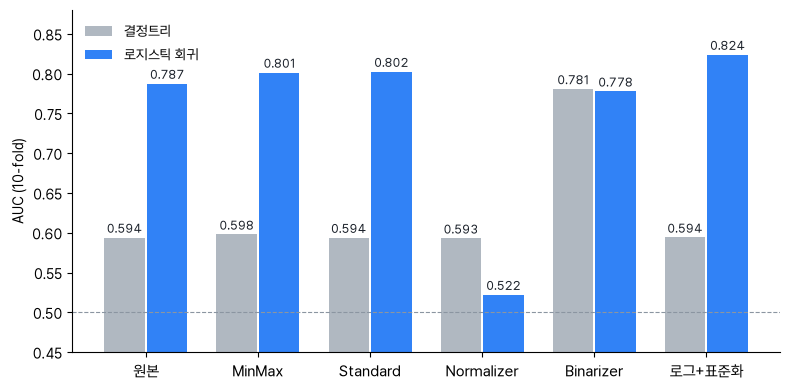

In [12]:
# 그림: 변환별 AUC
fig, ax = pyplot.subplots(figsize=(8, 4))
order = list(views)
xs = numpy.arange(len(order))
for k, (m, col) in enumerate([('결정트리', GRAY), ('로지스틱 회귀', BLUE)]):
    vals = result[result['모델'] == m].set_index('변환').loc[order, 'AUC']
    bars = ax.bar(xs + (k - 0.5) * 0.38, vals, width=0.36, color=col, label=m)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.006, f'{v:.3f}', ha='center', fontsize=9, color=INK)
ax.axhline(0.5, color='#8B95A1', lw=0.8, ls='--')
ax.set_xticks(xs); ax.set_xticklabels(order, fontsize=11)
ax.set_ylim(0.45, 0.88); ax.set_ylabel('AUC (10-fold)')
ax.spines[['top', 'right']].set_visible(False); ax.legend(frameon=False)
pyplot.tight_layout()
pyplot.savefig('../figures/lab2_auc_by_view.png', dpi=200)
pyplot.show()

## 정리: 발견 → 다음 질문

- 발견 1: **결정트리는 변환해도 AUC 0.59로 그대로**다. 값의 크기 순서만 보기 때문이다. 정확도 89.4%는 "모두 정상" 기준선(93.3%)보다도 낮다 → 과적합.
- 발견 2: **로지스틱 회귀는 변환에 민감**하다. 원본 0.788 → 표준화 0.803 → **로그+표준화 0.824**. Lab 2 본문대로 가중치를 쓰는 모델에 유용하다.
- 발견 3: **Normalizer는 0.522로 오히려 망가진다.** 행 단위로 길이를 1로 만들면 값이 큰 소득이 길이를 거의 다 차지한다 (희소 데이터용 방법).

**목표(연체 예측)에 대한 결론:** 가중치·거리 기반 모델(로지스틱 회귀, 이후 MLP)에는 **로그+표준화 데이터**를 쓴다.
트리 계열은 변환보다 **과적합 조절**이 과제다.

**다음 질문 (Lab 3):** 8개 변수가 다 필요할까? 그리고 정확도·한 번의 분할로 하는 지금 평가는 믿을 만할까?